# 00 | Genesis World 1.4.4 × Google Colab — 環境構築・Headless描画検証
**必ず先に実行。** 「ランタイム」→「ランタイムのタイプを変更」→ GPU (T4など)。Colabのカーネルを新規で起動してください。

成功条件：(a) Genesis import, (b) scene.build/step, (c) カメラPNG, (d) 3D mp4録画。`show_viewer=False`でGUI不要。
**このNotebookはデモの動作保証ではありません**。実際のColabランタイムで診断結果を確認してください。

In [1]:
import os
import sys
import subprocess
import platform
print('Python:', sys.version)
print('OS:', platform.platform())
subprocess.run(['nvidia-smi'], check = False)
import torch
print('PyTorch:', torch.__version__,'CUDA:', torch.cuda.is_available())
assert (3, 10) <= sys.version_info[:2] <= (3, 13), 'Genesis requires Python 3.10–3.13'

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
OS: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 CUDA: True


## システムライブラリ
EGL経由のGPUオフスクリーン描画を第一候補とし、OSMesaは**再起動後**の代替検証用。EGLドライバとCUDAドライバは別です。

In [2]:
!apt-get -qq update
!apt-get -qq install -y libegl1 libgl1 libgl1-mesa-dri libegl-mesa0 libosmesa6 libosmesa6-dev ffmpeg >/dev/null
!ldconfig -p | grep -E 'libEGL|libOSMesa|libGLX' | head -20

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
	libOSMesa.so.8 (libc6,x86-64) => /lib/x86_64-linux-gnu/libOSMesa.so.8
	libOSMesa.so (libc6,x86-64) => /lib/x86_64-linux-gnu/libOSMesa.so
	libGLX_mesa.so.0 (libc6,x86-64) => /lib/x86_64-linux-gnu/libGLX_mesa.so.0
	libGLX.so.0 (libc6,x86-64) => /lib/x86_64-linux-gnu/libGLX.so.0
	libGLX.so (libc6,x86-64) => /lib/x86_64-linux-gnu/libGLX.so
	libEGL_mesa.so.0 (libc6,x86-64) => /lib/x86_64-linux-gnu/libEGL_mesa.so.0
	libEGL.so.1 (libc6,x86-64) => /lib/x86_64-linux-gnu/libEGL.so.1


In [3]:
# 原則として既存のColab PyTorchは変更しません。Genesis 1.4.4 を固定します。
%pip -q install 'genesis-world==1.4.4' 'numpy<3' 'scipy<2' 'scikit-learn>=1.3,<2' 'pandas>=2,<3' 'matplotlib>=3.7,<4' 'opencv-python-headless>=4.8,<5' 'imageio-ffmpeg' 'nbformat>=5'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.4/41.4 kB 5.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.6/83.6 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 408.2/408.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 286.8/286.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.9/13.9 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.9/129.9 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━

## 描画環境選択
`PYOPENGL_PLATFORM=egl` をGenesis/PyOpenGLのimport前に指定。エラーが出たら **ランタイムを再起動**し、同じセルで `egl` を `osmesa` に変更して最初から実行。OSMesaはCPU描画になる場合があります。

In [4]:
import os
os.environ['PYOPENGL_PLATFORM'] = 'egl'  # retry ONLY after runtime restart using 'osmesa'
os.environ['PYGLET_HEADLESS'] = 'true'
import importlib.metadata as im
print('genesis-world version', im.version('genesis-world'))
import genesis as gs
import torch
backend = gs.cuda if torch.cuda.is_available() else gs.cpu
print('Backend:', backend)
gs.init(backend = backend, logging_level = 'warning')

genesis-world version 1.4.4
Backend: 2


## 最小シーン → PNG + MP4

/usr/local/lib/python3.13/dist-packages/quadrants/lang/ast/ast_transformers/call_transformer.py:295: DeprecationWarning: keyword.__init__ got an unexpected keyword argument 'ctx'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  kwarg_node = ast.keyword(


SUCCESS:  outputs/genesis_smoke.png outputs/genesis_smoke.mp4


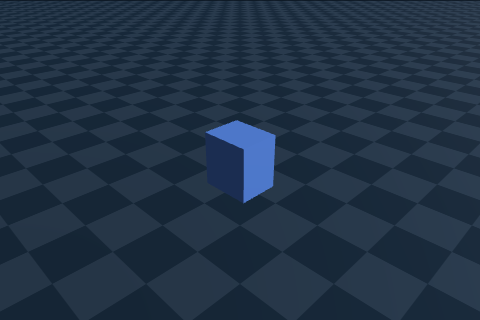

In [5]:
from pathlib import Path
from PIL import Image
import numpy as np
out = Path('outputs')
out.mkdir(exist_ok = True)
scene = gs.Scene(show_viewer = False, sim_options = gs.options.SimOptions(dt = 0.05))
scene.add_entity(gs.morphs.Plane())
scene.add_entity(gs.morphs.Box(pos = (0, 0, .3), size = (.55, .45, .6), fixed = True), surface = gs.surfaces.Plastic(color = (.3, .5, .9, 1)))
cam = scene.add_camera(res = (480, 320), pos = (2.5, -2.5, 2.2), lookat = (0, 0, .3), fov = 45, GUI = False)
scene.build()
scene.step()
rgb, *_ = cam.render()
a = np.asarray(rgb)
assert a.ndim==3 and a.shape[2]>=3, f'Invalid camera array: {a.shape}'
Image.fromarray(a[:, :, :3].astype('uint8')).save(out/'genesis_smoke.png')
cam.start_recording(save_to_filename = str((out/'genesis_smoke.mp4').resolve()), fps = 10)
for _ in range(40):
    scene.step()
cam.stop_recording()
assert (out/'genesis_smoke.mp4').exists(), 'MP4 missing'
print('SUCCESS: ', out/'genesis_smoke.png', out/'genesis_smoke.mp4')
from IPython.display import display, Video
display(Image.open(out/'genesis_smoke.png'))
display(Video(str(out/'genesis_smoke.mp4'), embed = True))

## 技術検証結果の保存
3D本編Notebook（02）は新しいランタイムで起動することを推奨します。Genesisのグローバル初期化の重複を避けます。

In [6]:
import json
import platform
import importlib.metadata
import torch
manifest={'python':platform.python_version(),'genesis_world':importlib.metadata.version('genesis-world'),
          'torch':torch.__version__,'cuda':torch.cuda.is_available(),'opengl':os.getenv('PYOPENGL_PLATFORM'),'smoke_pass':True}
(out/'environment_manifest.json').write_text(json.dumps(manifest, indent = 2), encoding = 'utf8')
print(manifest)

{'python': '3.13.15', 'genesis_world': '1.4.4', 'torch': '2.11.0+cu130', 'cuda': True, 'opengl': 'egl', 'smoke_pass': True}
